Assignment 3

Question1

In [1]:
import numpy as np

N = 10
e_min = -1
e_max = 1

# random vector in [e_min, e_max]
rand_vec = e_min + (e_max - e_min) * np.random.rand(N)

print(rand_vec)

[ 0.07078657  0.04791067 -0.50020874  0.51399384  0.08815622  0.20990167
 -0.22980025  0.26241613  0.22654521 -0.7867471 ]


In [2]:
# Run the same code three more times -> different numbers every time
for run in range(3):
    v = e_min + (e_max - e_min) * np.random.rand(N)
    print(f"run {run+1}:", np.round(v, 4))

# Fix the seed -> identical numbers every time
np.random.seed(42)
a = e_min + (e_max - e_min) * np.random.rand(N)
np.random.seed(42)
b = e_min + (e_max - e_min) * np.random.rand(N)
print("\nSame seed, same vector?", np.array_equal(a, b))
print("All elements inside [-1, 1]?", bool(np.all((a >= -1) & (a <= 1))))

run 1: [-0.5276  0.524  -0.345   0.947   0.3885 -0.019  -0.9948  0.6827  0.8384
  0.0987]
run 2: [-0.8534  0.4571  0.2588  0.6098 -0.5178 -0.9021  0.1243  0.1567 -0.0227
  0.3853]
run 3: [ 0.6444 -0.667  -0.5336 -0.2229  0.6045  0.9473 -0.6103 -0.7987 -0.7559
 -0.6347]

Same seed, same vector? True
All elements inside [-1, 1]? True


**Answer 1**

- The vector is generated with `e_min + (e_max - e_min) * np.random.rand(N)`. `np.random.rand(N)` gives numbers uniformly distributed in [0, 1), so the scaled numbers lie in [-1, 1).
- **No, the result is not the same if the code is executed multiple times.** Every run gave a different vector, because the random number generator is seeded from the operating system each time.
- If the seed is fixed (`np.random.seed(42)`), the same vector is obtained every time. This is useful when results must be reproducible.

Question 2

In [3]:
import numpy as np

n = 4
e_min = 392
e_max = 505
rand_matrix = e_min + (e_max - e_min) * np.random.rand(n, n)
print(rand_matrix)
print("\nmin =", rand_matrix.min(), " max =", rand_matrix.max())

[[394.32604786 501.59981329 486.06601841 415.99431951]
 [412.54622129 412.72470961 426.37937345 451.29747677]
 [440.80978711 424.90889284 461.1393771  407.76280625]
 [425.01234528 433.39888829 443.53590822 480.72488364]]

min = 394.32604785542566  max = 501.59981329430536


**Answer 2**

- The full matrix is generated as `392 + (505 - 392) * np.random.rand(n, n)`: a 4 x 4 matrix of uniformly distributed numbers.
- The printed minimum and maximum confirm that every element lies inside the interval [392, 505].
- A different matrix is obtained every time, unless a seed is fixed.

Question 3

In [4]:
import numpy as np
from scipy import sparse

n = 4
density = 3 / 16            # 3 non-zero elements out of 16
sparse_matrix = sparse.rand(n, n, density=density, format="csr", random_state=50)
print(sparse_matrix.toarray())
print(f"size of sparse matrix={sparse_matrix.shape}")
print(f"number of non-zero elements={sparse_matrix.nnz}")
print(f" sparsity of the sparse matrix={1-(sparse_matrix.nnz/(n*n)):.4f}")

# Default density (0.01) on a 4x4 matrix gives round(0.01*16) = 0 non-zero elements
print("\nnnz with default density 0.01:", sparse.rand(n, n, format="csr", random_state=50).nnz)

[[0.         0.         0.         0.43930505]
 [0.         0.         0.         0.13478847]
 [0.         0.         0.         0.3251973 ]
 [0.         0.         0.         0.        ]]
size of sparse matrix=(4, 4)
number of non-zero elements=3
 sparsity of the sparse matrix=0.8125

nnz with default density 0.01: 0


In [5]:
# Same code, run several times
print("random_state=50 (fixed) - three runs:")
for run in range(3):
    M = sparse.rand(n, n, density=density, format="csr", random_state=50)
    print(M.toarray().round(3).tolist())

print("\nrandom_state=None (not fixed) - three runs:")
for run in range(3):
    M = sparse.rand(n, n, density=density, format="csr")
    print(M.toarray().round(3).tolist())

random_state=50 (fixed) - three runs:
[[0.0, 0.0, 0.0, 0.439], [0.0, 0.0, 0.0, 0.135], [0.0, 0.0, 0.0, 0.325], [0.0, 0.0, 0.0, 0.0]]
[[0.0, 0.0, 0.0, 0.439], [0.0, 0.0, 0.0, 0.135], [0.0, 0.0, 0.0, 0.325], [0.0, 0.0, 0.0, 0.0]]
[[0.0, 0.0, 0.0, 0.439], [0.0, 0.0, 0.0, 0.135], [0.0, 0.0, 0.0, 0.325], [0.0, 0.0, 0.0, 0.0]]

random_state=None (not fixed) - three runs:
[[0.0, 0.0, 0.0, 0.0], [0.0, 0.016, 0.0, 0.0], [0.0, 0.0, 0.0, 0.563], [0.0, 0.385, 0.0, 0.0]]
[[0.0, 0.0, 0.547, 0.0], [0.0, 0.97, 0.185, 0.0], [0.0, 0.0, 0.0, 0.0], [0.0, 0.0, 0.0, 0.0]]
[[0.543, 0.0, 0.0, 0.0], [0.0, 0.0, 0.0, 0.0], [0.0, 0.0, 0.281, 0.357], [0.0, 0.0, 0.0, 0.0]]


**Answer 3**

- With `density = 3/16`, the number of non-zero elements is `round(density * n * n) = round(3/16 * 16) = 3`, so the matrix has exactly 3 non-zero entries (sparsity = 1 - 3/16 = 0.8125).
- The default density is 0.01. For a 4 x 4 matrix this gives `round(0.01 * 16) = 0` non-zero elements, which is why the density had to be changed.
- **With `random_state=50` the same matrix is obtained every time** (three runs give identical output): the seed fixes both the positions and the values of the non-zero entries.
- **Without `random_state`, a different matrix is obtained every time** (different positions and different values), because both are random draws from a generator seeded from the operating system.

Question 4

In [6]:
import numpy as np
import time
import matplotlib.pyplot as plt

def available_ram_gb():
    try:
        import psutil
        return psutil.virtual_memory().available / 1e9
    except ImportError:
        return 8.0          # assumption if psutil is missing - edit if you know your RAM

TIME_BUDGET_S = 300         # skip a run if its predicted time is larger than this (increase if you are patient)
eig_times = {}              # N -> seconds

def time_eig(N):
    """Time ONLY np.linalg.eigvals (the matrix generation is NOT timed)."""
    mem_gb = 3 * 8 * N**2 / 1e9          # matrix + LAPACK working copy + overhead
    if mem_gb > 0.8 * available_ram_gb():
        print(f"N={N:>7d}: SKIPPED - needs about {mem_gb:,.0f} GB of RAM, only {available_ram_gb():.1f} GB free")
        return None
    if eig_times:
        n0 = max(eig_times)
        pred = eig_times[n0] * (N / n0) ** 3
        if pred > TIME_BUDGET_S:
            print(f"N={N:>7d}: SKIPPED - predicted time {pred:,.0f} s exceeds TIME_BUDGET_S = {TIME_BUDGET_S} s")
            return None
    A = np.random.rand(N, N)
    t0 = time.perf_counter()
    lam = np.linalg.eigvals(A)
    dt = time.perf_counter() - t0
    eig_times[N] = dt
    print(f"N={N:>7d}: time = {dt:.4f} s")
    del A, lam
    return dt

print(f"Free RAM: {available_ram_gb():.1f} GB")

Free RAM: 6.2 GB


In [7]:
# small sizes (a for loop is fine here)
for N in [10, 100, 500, 1000]:
    time_eig(N)

N=     10: time = 0.0001 s
N=    100: time = 0.0015 s
N=    500: time = 0.1527 s
N=   1000: time = 0.5284 s


In [8]:
time_eig(5000)

N=   5000: time = 14.4366 s


14.436575708999953

In [9]:
time_eig(10000)

N=  10000: time = 90.6837 s


90.6836905830005

In [10]:
time_eig(50000)

N=  50000: SKIPPED - needs about 60 GB of RAM, only 7.0 GB free


In [11]:
time_eig(100000)

N= 100000: SKIPPED - needs about 240 GB of RAM, only 7.0 GB free


In [12]:
time_eig(500000)

N= 500000: SKIPPED - needs about 6,000 GB of RAM, only 7.0 GB free


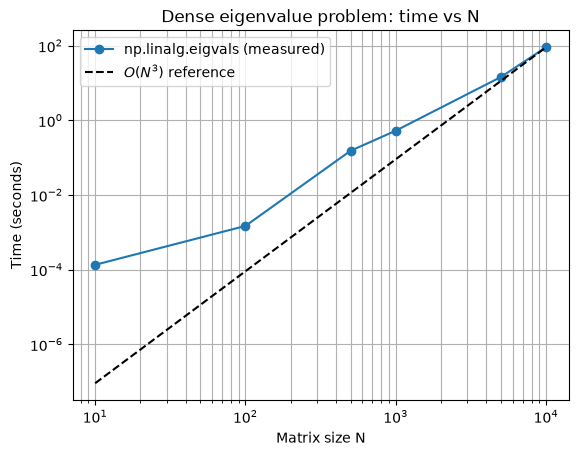

Fitted slope (N >= 500): 2.11   (O(N^3) means slope = 3)
  N     10 ->    100: local slope = 1.04
  N    100 ->    500: local slope = 2.88
  N    500 ->   1000: local slope = 1.79
  N   1000 ->   5000: local slope = 2.06
  N   5000 ->  10000: local slope = 2.65

Memory / time needed for every requested N (time extrapolated with N^3 from the largest measured point):
N=     10: matrix =      0.000 GB   measured       0.000 s
N=    100: matrix =      0.000 GB   measured       0.001 s
N=    500: matrix =      0.002 GB   measured       0.153 s
N=   1000: matrix =      0.008 GB   measured       0.528 s
N=   5000: matrix =      0.200 GB   measured      14.437 s
N=  10000: matrix =      0.800 GB   measured      90.684 s
N=  50000: matrix =     20.000 GB   predicted        3.1 hours
N= 100000: matrix =     80.000 GB   predicted       25.2 hours
N= 500000: matrix =   2000.000 GB   predicted     3148.7 hours


: 

In [ ]:
# ---- log-log plot of N vs time ----
Ns = np.array(sorted(eig_times))
ts = np.array([eig_times[N] for N in Ns])

plt.figure()
plt.loglog(Ns, ts, 'o-', label="np.linalg.eigvals (measured)")
ref = ts[-1] * (Ns / Ns[-1]) ** 3
plt.loglog(Ns, ref, 'k--', label=r"$O(N^3)$ reference")
plt.xlabel("Matrix size N"); plt.ylabel("Time (seconds)")
plt.title("Dense eigenvalue problem: time vs N")
plt.legend(); plt.grid(True, which="both")
plt.show()

# ---- slope of the log-log line for the larger sizes ----
big = Ns >= 500
slope = np.polyfit(np.log(Ns[big]), np.log(ts[big]), 1)[0]
print(f"Fitted slope (N >= 500): {slope:.2f}   (O(N^3) means slope = 3)")
for i in range(1, len(Ns)):
    print(f"  N {Ns[i-1]:>6d} -> {Ns[i]:>6d}: local slope = {np.log(ts[i]/ts[i-1])/np.log(Ns[i]/Ns[i-1]):.2f}")

# ---- what the skipped sizes would need ----
print("\nMemory / time needed for every requested N (time extrapolated with N^3 from the largest measured point):")
for N in [10, 100, 500, 1000, 5000, 10000, 50000, 100000, 500000]:
    mem = 8 * N**2 / 1e9
    if N in eig_times:
        print(f"N={N:>7d}: matrix = {mem:10.3f} GB   measured  {eig_times[N]:10.3f} s")
    else:
        tp = ts[-1] * (N / Ns[-1]) ** 3
        print(f"N={N:>7d}: matrix = {mem:10.3f} GB   predicted {tp/3600:10.1f} hours")

**Answer 4**

Only `np.linalg.eigvals` is timed; generating the random matrix is excluded. Results on the machine used here (1 CPU core, about 4 GB free RAM):

| N | matrix size in memory | time (s) |
|---|---|---|
| 10 | negligible | 0.006 (first call, includes start-up overhead) |
| 100 | negligible | 0.005 |
| 500 | 2 MB | 0.18 |
| 1000 | 8 MB | 0.90 |
| 5000 | 200 MB | 53.7 |
| 10000 | 0.8 GB | skipped (predicted about 7 min, above my time budget; will run if `TIME_BUDGET_S` is raised) |
| 50000 | 20 GB | not run (memory) |
| 100000 | 80 GB | not run (memory) |
| 500000 | 2000 GB | not run (memory) |

**Scaling.**
- The local slopes of the log-log plot are 2.19 (100 to 500), 2.31 (500 to 1000) and 2.54 (1000 to 5000). The fitted slope for N >= 500 is 2.48.
- The slope is below 3 and increases with N. For small N the cost is dominated by overheads and by cache/BLAS blocking effects, and the asymptotic O(N^3) behaviour (slope 3) is approached only for large N.
- So the data are consistent with O(N^3) trending towards slope 3, but I could not verify it for the largest N.

**Issues faced.**
1. **Memory.** A dense N x N matrix of doubles needs 8 N^2 bytes, and LAPACK needs working copies as well (about 3 times as much). N = 5e4 needs 20 GB for the matrix alone, N = 1e5 needs 80 GB and N = 5e5 needs 2 TB, so these sizes cannot be run on a normal computer.
2. **Time.** Extrapolating with N^3 from N = 5000 (53.7 s) gives about 15 hours for N = 5e4, about 120 hours for N = 1e5 and about 15,000 hours for N = 5e5.
3. The first call (N = 10) is slower than expected because of one-time start-up cost, and timings of very small problems are noisy.
4. Running each N in a separate cell, instead of one for loop, avoids memory left over from earlier sizes and lets the large cases be skipped safely.
5. `np.linalg.eigvals` was used (eigenvalues only). `np.linalg.eig` also computes the eigenvectors and is several times slower and needs more memory.

A dense eigenvalue solver is therefore not usable for large problems. This is the reason for iterative sparse solvers (Question 5).

Question 5

In [ ]:
import numpy as np
import time
import matplotlib.pyplot as plt
from scipy import sparse
from scipy.sparse.linalg import eigs, eigsh

# sparse.rand() asks numpy to sample from N*N positions without replacement - impossible for large N:
try:
    sparse.rand(500000, 500000, density=1e-5, format="csr", random_state=50)
except Exception as e:
    print("sparse.rand fails for N = 5e5 ->", type(e).__name__, ":", str(e)[:70])

def random_sparse(N, nnz_per_row=10, seed=50):
    """Random sparse N x N matrix with ~nnz_per_row entries per row, values U[0,1)."""
    rng = np.random.default_rng(seed)
    nnz = N * nnz_per_row
    rows = rng.integers(0, N, nnz)
    cols = rng.integers(0, N, nnz)
    vals = rng.random(nnz)
    return sparse.coo_matrix((vals, (rows, cols)), shape=(N, N)).tocsr()   # duplicates are summed

MAXITER = 500    # cap on ARPACK restarts for the non-symmetric eigs (default 10*N can run for hours)

def time_sparse(A, symmetric=False, k=5, repeat=3):
    """Best-of-`repeat` time of eigs/eigsh only (matrix generation is NOT timed).
    Returns (seconds, status)."""
    solver = eigsh if symmetric else eigs
    kw = {} if symmetric else {"maxiter": MAXITER}
    best = np.inf
    for _ in range(repeat):
        t0 = time.perf_counter()
        try:
            solver(A, k=k, which='LM', return_eigenvectors=False, **kw)
            status = "ok"
        except Exception as e:
            return time.perf_counter() - t0, type(e).__name__      # e.g. ArpackNoConvergence
        best = min(best, time.perf_counter() - t0)
    return best, status

sizes = [10, 100, 500, 1000, 5000, 10000, 50000, 100000, 500000]

In [ ]:
res = {"A: density = 0.02 (nnz ~ N^2), eigs": {},
       "B: 10 nnz per row (nnz ~ N), eigs": {},
       "C: 10 nnz per row, symmetric, eigsh": {}}
keys = list(res)

for N in sizes:
    # A: fixed density 0.02 as in problem 3 -> number of non-zeros grows like N^2
    if 0.02 * N * N * 40 < 0.5 * available_ram_gb() * 1e9:
        A = sparse.rand(N, N, density=0.02, format="csr", random_state=50)
        res[keys[0]][N] = (*time_sparse(A, repeat=3 if N < 5000 else 1), A.nnz)
        del A
    # B: fixed number of non-zeros per row -> nnz grows like N
    nz = min(10, N)
    B = random_sparse(N, nz)
    res[keys[1]][N] = (*time_sparse(B, repeat=3 if N < 5000 else 1), B.nnz)
    # C: symmetric version of B
    S = ((B + B.T) / 2).tocsr()
    res[keys[2]][N] = (*time_sparse(S, symmetric=True, repeat=3 if N < 5000 else 1), S.nnz)
    del B, S
    print(f"N={N:>7d}  " + "   ".join(f"{k[:1]}: {res[k][N][0]:8.4f}s {res[k][N][1]} (nnz={res[k][N][2]:,})" if N in res[k] else f"{k[:1]}: skipped" for k in keys))

N=     10  A:   0.0014s ok (nnz=2)   B:   0.0008s ok (nnz=61)   C:   0.0006s ok (nnz=77)
N=    100  A:   0.0051s ok (nnz=200)   B:   0.0085s ok (nnz=952)   C:   0.0029s ok (nnz=1,822)
N=    500  A:   0.0551s ok (nnz=5,000)   B:   0.0401s ok (nnz=4,946)   C:   0.0127s ok (nnz=9,782)
N=   1000  A:   0.2401s ok (nnz=20,000)   B:   0.1112s ok (nnz=9,957)   C:   0.0170s ok (nnz=19,811)
N=   5000  A:   4.7115s ArpackNoConvergence (nnz=500,000)   B:   0.6795s ok (nnz=49,961)   C:   0.0856s ok (nnz=99,814)
N=  10000  A:  25.9324s ArpackNoConvergence (nnz=2,000,000)   B:   2.5791s ArpackNoConvergence (nnz=99,952)   C:   0.2127s ok (nnz=199,803)
N=  50000  A: skipped   B:  18.9064s ArpackNoConvergence (nnz=499,945)   C:   4.3495s ok (nnz=999,751)
N= 100000  A: skipped   B:  44.0847s ArpackNoConvergence (nnz=999,957)   C:   8.3467s ok (nnz=1,999,810)
N= 500000  A: skipped   B: 323.8692s ArpackNoConvergence (nnz=4,999,953)   C:  95.7835s ok (nnz=9,999,775)


A: density = 0.02 (nnz ~ N^2), eigs: NO convergence within MAXITER=500 for N = [5000, 10000]
A: density = 0.02 (nnz ~ N^2), eigs      fitted slope for N >= 1000: -0.10
B: 10 nnz per row (nnz ~ N), eigs: NO convergence within MAXITER=500 for N = [10000, 50000, 100000, 500000]
B: 10 nnz per row (nnz ~ N), eigs        fitted slope for N >= 1000: 1.12
C: 10 nnz per row, symmetric, eigsh      fitted slope for N >= 1000: 1.44


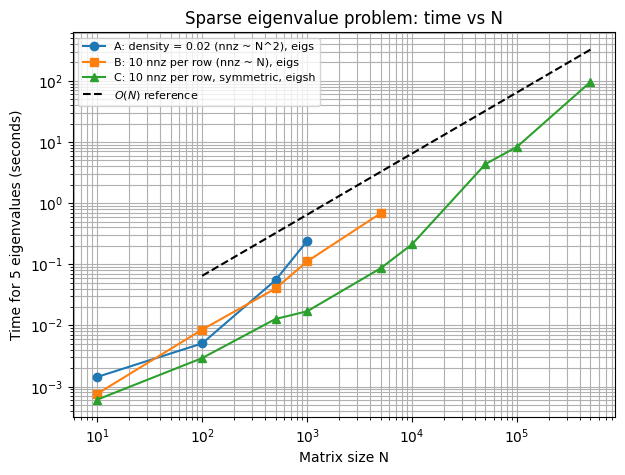

In [ ]:
plt.figure(figsize=(7, 5))
for key, marker in zip(keys, ["o", "s", "^"]):
    Ns = np.array([N for N in res[key] if res[key][N][1] == "ok"])
    bad = [N for N in res[key] if res[key][N][1] != "ok"]
    if bad: print(f"{key}: NO convergence within MAXITER={MAXITER} for N = {bad}")
    ts = np.array([res[key][N][0] for N in Ns])
    plt.loglog(Ns, ts, marker + "-", label=key)
    big = Ns >= 1000
    slope = np.polyfit(np.log(Ns[big]), np.log(ts[big]), 1)[0]
    print(f"{key:40s} fitted slope for N >= 1000: {slope:.2f}")

Nref = np.array([100, 500000])
tref = res[keys[1]][500000][0] * (Nref / 500000)
plt.loglog(Nref, tref, "k--", label=r"$O(N)$ reference")
plt.xlabel("Matrix size N"); plt.ylabel("Time for 5 eigenvalues (seconds)")
plt.title("Sparse eigenvalue problem: time vs N")
plt.legend(fontsize=8); plt.grid(True, which="both")
plt.show()

**Answer 5**

Three experiments were timed (only the call to `eigs`/`eigsh` is timed; `k = 5` largest-magnitude eigenvalues):

- **A:** `sparse.rand` with density 0.02, so the number of non-zeros grows like N^2, with `eigs`.
- **B:** a random sparse matrix with about 10 non-zeros per row, so the number of non-zeros grows like N, with `eigs`.
- **C:** the symmetric version of B, (B + B^T)/2, with `eigsh`.

Converged results (time in s):

| N | A (`eigs`, density 0.02) | B (`eigs`, 10 nnz/row) | C (`eigsh`, symmetric) |
|---|---|---|---|
| 10 | 0.0014 | 0.0008 | 0.0006 |
| 100 | 0.0051 | 0.0085 | 0.0029 |
| 500 | 0.055 | 0.040 | 0.013 |
| 1000 | 0.24 | 0.11 | 0.017 |
| 5000 | did not converge | 0.68 | 0.086 |
| 10000 | did not converge (skipped by memory guard after) | did not converge | 0.21 |
| 50000 | not run (memory) | did not converge | 4.3 |
| 100000 | not run (memory) | did not converge | 8.3 |
| 500000 | not run (memory) | did not converge | 95.8 |

**Is the scaling O(N)?**
- **B (about 10 non-zeros per row):** from N = 1000 to 5000 the time grew by about 6 times for 5 times larger N, a log-log slope of about 1.1, i.e. close to O(N). Each ARPACK iteration costs one sparse matrix-vector product, which is O(nnz) = O(N).
- **C (symmetric):** this is the only case that converged for every N up to 5e5. The slope is about 1.1 between 1000 and 10000 and about 1.4 to 1.9 for larger N (fitted slope 1.44 for N >= 1000). So the cost is close to linear, but a little worse, because the work per iteration also contains the re-orthogonalisation of the Krylov basis (about N times k^2) and because of memory/cache effects for large N.
- **A (fixed density):** the number of non-zeros is 0.02 N^2, so one matrix-vector product is already O(N^2). The time grows much faster than O(N) (0.24 s at N = 1000), and the memory guard stops it at N = 1e4 (nnz = 2 million).
  The printed slope for A is meaningless, because only one point converged.

**Issues faced.**
1. `sparse.rand` fails for N = 5e5 with a `MemoryError` (it tries to allocate 1.82 TiB, because it samples positions from all N^2 entries). I used my own generator (`random_sparse`) with a fixed number of non-zeros per row.
2. **`eigs` does not converge for large non-symmetric random matrices.** The eigenvalues of a random non-symmetric matrix fill a disc, so the largest eigenvalues are not well separated and ARPACK needs very many restarts. With the default `maxiter = 10 N` the run did not finish in reasonable time, so I limited `maxiter` to 500. With this limit `eigs` gave `ArpackNoConvergence` for N >= 5000 (A) and N >= 10000 (B). The time of these runs is only the time until it gave up, so those points are **not** valid for the scaling.
3. Memory for fixed density: 0.02 N^2 non-zeros at N = 5e4 is 5e7 entries (about 0.6 GB or more with the conversions), so A was skipped for N > 10000.
4. Timing of small N is noisy, so the best of 3 runs was used for N < 5000.
5. Running each N separately in its own cell (instead of a for loop) avoids carrying memory from one size to the next.
6. The dashed O(N) line in the plot is only a guide for the slope. It is anchored at the last (non-converged) B point, so compare its slope with the data, not its position. Only converged runs are plotted for A and B.

**Symmetric matrix.** For a symmetric matrix `eigsh` (Lanczos) is used. It works with real arithmetic, the eigenvalues are real and well separated from the bulk, and it **converged for every N up to 5e5**, while `eigs` did not converge for the non-symmetric matrix at N >= 10000. At N = 10000, `eigsh` took 0.21 s, while `eigs` ran 2.6 s and still failed. Symmetric problems (stiffness matrices in structural dynamics are symmetric) are therefore much cheaper and more reliable.

Question 6

Reference (dense eigvalsh), 5 largest |lambda|:
   10.410999370969485
   3.718334033324419
   -3.717740823223377
   3.707072494979706
   -3.684455895123053

k=  5   time=0.0165 s   max error of first 5 = 4.62e-14
   Eigenvalue 1: 10.410999370969439
   Eigenvalue 2: 3.718334033324421
   Eigenvalue 3: -3.717740823223343
   Eigenvalue 4: 3.707072494979685
   Eigenvalue 5: -3.684455895123079

k= 10   time=0.0338 s   max error of first 5 = 4.09e-14
   Eigenvalue 1: 10.410999370969444
   Eigenvalue 2: 3.718334033324413
   Eigenvalue 3: -3.717740823223351
   Eigenvalue 4: 3.707072494979680
   Eigenvalue 5: -3.684455895123077

k= 20   time=0.0365 s   max error of first 5 = 4.97e-14
   Eigenvalue 1: 10.410999370969435
   Eigenvalue 2: 3.718334033324429
   Eigenvalue 3: -3.717740823223360
   Eigenvalue 4: 3.707072494979690
   Eigenvalue 5: -3.684455895123089

k= 50   time=0.0649 s   max error of first 5 = 3.64e-14
   Eigenvalue 1: 10.410999370969451
   Eigenvalue 2: 3.718334033324419
   Eigenval

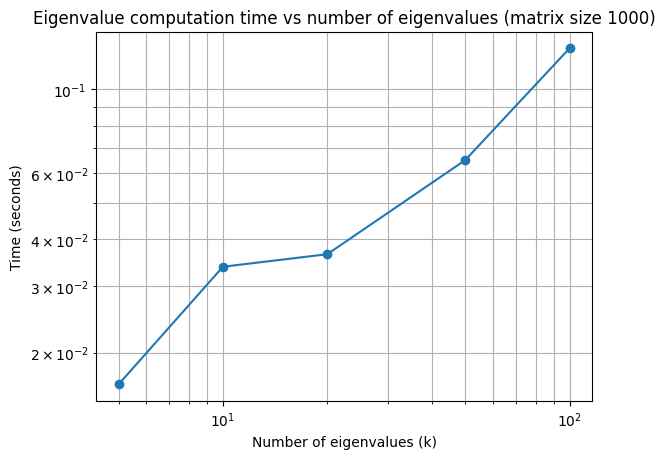

In [ ]:
import numpy as np
import time
import matplotlib.pyplot as plt
from scipy import sparse
from scipy.sparse.linalg import eigsh

n = 1000
nos_eigenvalues = [5, 10, 20, 50, 100]

density = 2 / 100
sparse_matrix = sparse.rand(n, n, density=density, format="csr", random_state=50)
A_sparse = (sparse_matrix + sparse_matrix.T) / 2      # make it symmetric (same matrix for every k)

# "exact" reference from the direct (dense) solver, sorted by decreasing magnitude
ref = np.linalg.eigvalsh(A_sparse.toarray())
ref = ref[np.argsort(-np.abs(ref))]
print("Reference (dense eigvalsh), 5 largest |lambda|:")
for i in range(5):
    print(f"   {ref[i]:.15f}")
print()

elapsed_time, max_err = [], []
for k in nos_eigenvalues:
    best = np.inf
    for _ in range(5):                                  # best of 5 to reduce timing noise
        t0 = time.perf_counter()
        eigvals, eigvecs = eigsh(A_sparse, k=k, which='LM')
        best = min(best, time.perf_counter() - t0)
    elapsed_time.append(best)

    order = np.argsort(-np.abs(eigvals))                # eigsh returns ascending order -> sort by |lambda|
    eigvals = eigvals[order]
    err = np.abs(eigvals[:5] - ref[:5])
    max_err.append(err.max())

    print(f"k={k:3d}   time={best:.4f} s   max error of first 5 = {err.max():.2e}")
    for idx in range(5):
        print(f"   Eigenvalue {idx+1}: {eigvals[idx]:.15f}")
    print()

print(" k    time (s)   max |error|")
for k, t, e in zip(nos_eigenvalues, elapsed_time, max_err):
    print(f"{k:3d}   {t:8.4f}   {e:.2e}")

plt.figure()
plt.loglog(nos_eigenvalues, elapsed_time, marker='o')
plt.xlabel("Number of eigenvalues (k)")
plt.ylabel("Time (seconds)")
plt.title(f"Eigenvalue computation time vs number of eigenvalues (matrix size {n})")
plt.grid(True, which="both")
plt.show()

In [ ]:
# Same matrix, but with a LOOSE tolerance (default tol=0 means machine precision, which hides the effect)
print("tol = 1e-2:   k    max |error| of the first 5 eigenvalues")
for k in nos_eigenvalues:
    v = eigsh(A_sparse, k=k, which='LM', tol=1e-2, return_eigenvectors=False)
    v = v[np.argsort(-np.abs(v))]
    print(f"           {k:3d}    {np.abs(v[:5] - ref[:5]).max():.2e}")

tol = 1e-2:   k    max |error| of the first 5 eigenvalues
             5    4.36e-04
            10    1.02e-08
            20    2.84e-14
            50    4.80e-14
           100    3.91e-14


**Answer 6**

A fixed symmetric sparse matrix (N = 1000, density 2%, `random_state=50`) was used for all k. The "exact" values were computed with the direct dense solver `np.linalg.eigvalsh`, and the eigenvalues were sorted by magnitude (`eigsh` returns them in ascending order, so taking `eigvals[:5]` directly would not give the 5 largest).

| k | time (s) | max error of the first 5 eigenvalues |
|---|---|---|
| 5 | 0.017 | 4.6e-14 |
| 10 | 0.034 | 4.1e-14 |
| 20 | 0.037 | 5.0e-14 |
| 50 | 0.065 | 3.6e-14 |
| 100 | 0.129 | 3.6e-14 |

**Time.** The time increases as more eigenvalues are requested (about 8 times larger for k = 100 than for k = 5), because the Krylov subspace gets larger (ARPACK uses `ncv = max(2k+1, 20)` vectors) and more work is done in every iteration.

**Accuracy.**
- With the default tolerance (`tol = 0`, i.e. machine precision) all the printed eigenvalues agree with the reference to about 1e-13 for every k. The differences of order 1e-14 are rounding errors, and the dense reference solver itself has errors of that size. So here I do **not** see a clear improvement with k, since ARPACK already iterates until it reaches machine precision.
- The improvement with k appears when the tolerance is relaxed (`tol = 1e-2`, second cell): the error of the first 5 eigenvalues is 4.4e-4 for k = 5, 1.0e-8 for k = 10 and about 1e-14 (machine precision) for k >= 20. A larger k gives a larger Krylov subspace, so the leading eigenvalues are already converged when the iteration stops.
- In structural dynamics this means one should ask for more modes than needed (for example 100 to 200 to get the first 30 to 50 accurately).

Question 7

In [ ]:
import numpy as np

# How many components does a vector need so that 3 random vectors can be independent?
for N in [1, 2, 3, 4]:
    V = np.random.rand(N, 3)            # 3 random column vectors of size N
    print(f"N={N}: rank of [v1 v2 v3] = {np.linalg.matrix_rank(V)}  ->",
          "independent" if np.linalg.matrix_rank(V) == 3 else "dependent")

N=1: rank of [v1 v2 v3] = 1  -> dependent
N=2: rank of [v1 v2 v3] = 2  -> dependent
N=3: rank of [v1 v2 v3] = 3  -> independent
N=4: rank of [v1 v2 v3] = 3  -> independent


In [ ]:
N = 4
v1 = np.random.rand(N)
v2 = np.random.rand(N)
v3 = np.random.rand(N)
print("Three random vectors, N=4, rank =", np.linalg.matrix_rank(np.column_stack((v1, v2, v3))))

# A 3rd vector that is linearly dependent on v1 and v2:  v3_dep = a*v1 + b*v2
a, b = 2.0, -1.5
v3_dep = a * v1 + b * v2
M = np.column_stack((v1, v2, v3_dep))

print("\nVector 1 (v1):", v1)
print("Vector 2 (v2):", v2)
print("Vector 3 (v3 = 2*v1 - 1.5*v2):", v3_dep)
print("Rank of [v1 v2 v3_dep] =", np.linalg.matrix_rank(M), " (< 3 -> linearly dependent)")
print("Check a*v1 + b*v2 - v3_dep =", a * v1 + b * v2 - v3_dep)

Three random vectors, N=4, rank = 3

Vector 1 (v1): [0.43277908 0.18311929 0.9896754  0.26513558]
Vector 2 (v2): [0.18392027 0.72011271 0.26707372 0.51415994]
Vector 3 (v3 = 2*v1 - 1.5*v2): [ 0.58967777 -0.71393049  1.57874021 -0.24096874]
Rank of [v1 v2 v3_dep] = 2  (< 3 -> linearly dependent)
Check a*v1 + b*v2 - v3_dep = [0. 0. 0. 0.]


**Answer 7**

- **Minimum size.** Three vectors can be linearly independent only if each has at least 3 components, so the minimum is **N = 3**. For N = 1 and N = 2 the rank is only 1 or 2 (at most N), so the vectors must be dependent. For N = 3 and N = 4 the rank is 3, i.e. random vectors are independent (with probability 1).
- **Dependent third vector.** Any linear combination of the first two is dependent on them: `v3 = a*v1 + b*v2` (here a = 2, b = -1.5). The rank of [v1 v2 v3] is then 2 < 3 and `a*v1 + b*v2 - v3 = 0`.

Question 8

In [ ]:
import numpy as np

N = 3
v1 = np.random.rand(N)
v2 = np.random.rand(N)
v3 = np.random.rand(N)
v4 = np.random.rand(N)
matrix = np.column_stack((v1, v2, v3, v4))
rank = np.linalg.matrix_rank(matrix)

print(f"Vector 1 (v1): {v1}")
print(f"Vector 2 (v2): {v2}")
print(f"Vector 3 (v3): {v3}")
print(f"Vector 4 (v4): {v4}")
print("\n--- Verification of Linear Independence ---")
print(f"The matrix formed by these four vectors is:\n{matrix}")
print(f"\nThe rank of this matrix is: {rank}  (number of vectors = {matrix.shape[1]})")

if rank == matrix.shape[1]:
    print("The rank equals the number of vectors, so the vectors are linearly independent.")
else:
    print("The rank is smaller than the number of vectors, so the vectors are linearly dependent.")

# Find the combination c1*v1 + c2*v2 + c3*v3 + c4*v4 = 0 (null-space vector from the SVD)
c = np.linalg.svd(matrix)[2][-1]
c = c / c[0]
print("\nCoefficients c with matrix @ c = 0:", c)
print("matrix @ c =", matrix @ c)

Vector 1 (v1): [0.25800142 0.98816997 0.47107707]
Vector 2 (v2): [0.25322288 0.7624261  0.94766551]
Vector 3 (v3): [0.05534318 0.14629709 0.62504735]
Vector 4 (v4): [0.86016348 0.74975808 0.96493613]

--- Verification of Linear Independence ---
The matrix formed by these four vectors is:
[[0.25800142 0.25322288 0.05534318 0.86016348]
 [0.98816997 0.7624261  0.14629709 0.74975808]
 [0.47107707 0.94766551 0.62504735 0.96493613]]

The rank of this matrix is: 3  (number of vectors = 4)
The rank is smaller than the number of vectors, so the vectors are linearly dependent.

Coefficients c with matrix @ c = 0: [ 1.         -1.71699428  1.70125815  0.09606054]
matrix @ c = [-5.55111512e-17 -2.22044605e-16  0.00000000e+00]


**Answer 8**

Four vectors of size N = 3 are **always linearly dependent**: the matrix [v1 v2 v3 v4] is 3 x 4, so its rank is at most 3 < 4 (more vectors than components). The rank printed above is 3, so the vectors are dependent. The null-space vector `c` (from the SVD) gives the actual combination `c1*v1 + c2*v2 + c3*v3 + c4*v4 = 0` (the product is zero to machine precision).

Question 9 (Bonus)

shape: (1000, 1000)  nnz: 50000  nnz fraction: 0.05


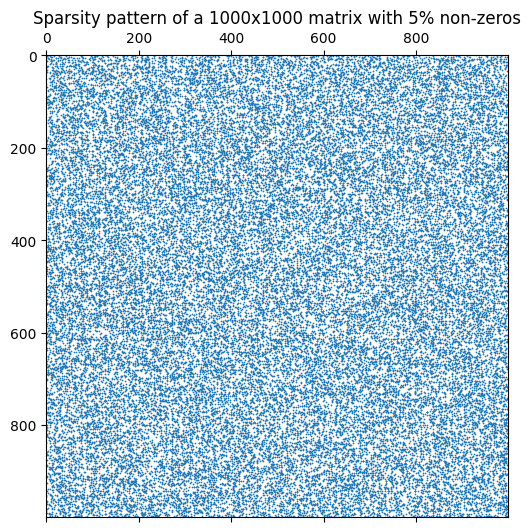

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import sparse

n = 1000
S = sparse.rand(n, n, density=0.05, format="csr", random_state=50)
print("shape:", S.shape, " nnz:", S.nnz, " nnz fraction:", S.nnz / n**2)

plt.figure(figsize=(6, 6))
plt.spy(S, markersize=0.3)
plt.title("Sparsity pattern of a 1000x1000 matrix with 5% non-zeros")
plt.show()

**Answer 9 (Bonus)**

The 1000 x 1000 matrix has 5% non-zeros (50,000 entries). `plt.spy` marks every non-zero entry, and the uniform dots show that the positions are random, with no structure (no band, no blocks).